# Q3 - Win rate, K/D and streaks per player

1. Win rate and K/D ratio for all players.
2. Longest win streak and longest loss streak for players with at least 3 matches.

Choices:
- A win is victory = TRUE, a loss is victory = FALSE. draw / other (56 rows) count as neither.
- K/D only uses rows where kills and death are filled (the incident day is left out).
- All game modes are kept.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))  # not needed after `pip install -e .`

from ubi_churn.config import DataCatalog, load_params

catalog = DataCatalog.from_config()  # conf/base/catalog.yml
params = load_params()  # conf/base/parameters.yml

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

from ubi_churn.utils import exploration as ex

ex.set_plot_style()
MIN_MATCHES: int = params['exploration']['min_matches_streak']

df_player_matches: pl.DataFrame = catalog.load('player_matches')
print(df_player_matches.shape, '| players:', df_player_matches['playerid'].n_unique())

(95733, 11) | players: 840


## 1. Win / lose per player

In [2]:
df_player_stats: pl.DataFrame = ex.win_kd_stats(df_player_matches)
print('players with no decided match (win rate undefined):', df_player_stats.filter(pl.col('decided') == 0).height)
print(df_player_stats.select('matches', 'win_rate', 'kd_ratio').describe())

players with no decided match (win rate undefined): 0
shape: (9, 4)
┌────────────┬────────────┬──────────┬──────────┐
│ statistic  ┆ matches    ┆ win_rate ┆ kd_ratio │
│ ---        ┆ ---        ┆ ---      ┆ ---      │
│ str        ┆ f64        ┆ f64      ┆ f64      │
╞════════════╪════════════╪══════════╪══════════╡
│ count      ┆ 840.0      ┆ 840.0    ┆ 833.0    │
│ null_count ┆ 0.0        ┆ 0.0      ┆ 7.0      │
│ mean       ┆ 113.967857 ┆ 0.463152 ┆ 0.897528 │
│ std        ┆ 214.27     ┆ 0.228459 ┆ 0.587972 │
│ min        ┆ 1.0        ┆ 0.0      ┆ 0.0      │
│ 25%        ┆ 5.0        ┆ 0.391447 ┆ 0.52381  │
│ 50%        ┆ 28.0       ┆ 0.489051 ┆ 0.862825 │
│ 75%        ┆ 111.0      ┆ 0.54902  ┆ 1.171053 │
│ max        ┆ 1974.0     ┆ 1.0      ┆ 5.0      │
└────────────┴────────────┴──────────┴──────────┘


In [3]:
# still_active should be a player attribute (constant per player): check, then build player x gamemode stats
print('players with several still_active values:', df_player_matches.group_by('playerid').agg(pl.col('still_active').n_unique().alias('n')).filter(pl.col('n') > 1).height)

GAMEMODE_ORDER: list[str] = params['exploration']['gamemode_order']  # OPERATIONS (5 rows) left out
MIN_DECIDED_PLOT: int = params['exploration']['min_decided_plot']  # below this, a player rate is mostly noise

df_player_mode: pl.DataFrame = ex.win_kd_stats(
    df_player_matches.filter(pl.col('gamemode').is_in(GAMEMODE_ORDER)), by=('playerid', 'gamemode', 'still_active'),
).with_columns(ex.activity_label())
print(df_player_mode.group_by('gamemode', 'activity').len().sort('gamemode', 'activity'))

players with several still_active values: 0
shape: (6, 3)
┌──────────────┬──────────┬─────┐
│ gamemode     ┆ activity ┆ len │
│ ---          ┆ ---      ┆ --- │
│ str          ┆ str      ┆ u32 │
╞══════════════╪══════════╪═════╡
│ PVP          ┆ Active   ┆ 314 │
│ PVP          ┆ Inactive ┆ 411 │
│ PVP_RANKED   ┆ Active   ┆ 230 │
│ PVP_RANKED   ┆ Inactive ┆ 144 │
│ PVP_UNRANKED ┆ Active   ┆ 273 │
│ PVP_UNRANKED ┆ Inactive ┆ 235 │
└──────────────┴──────────┴─────┘


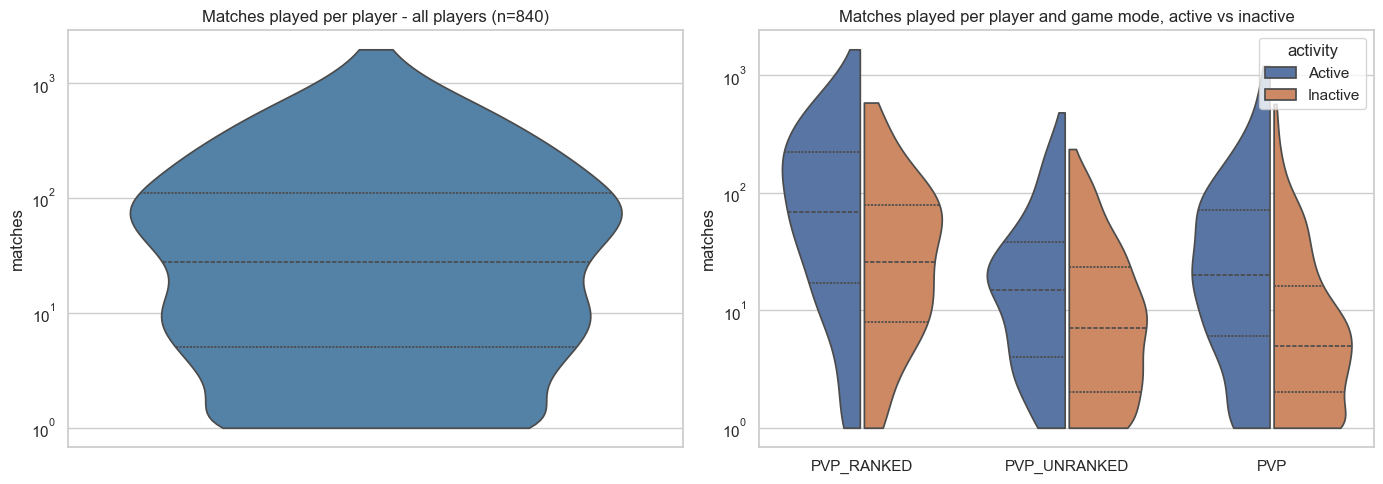

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 840.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 113.967857 │
│ std        ┆ 214.27     │
│ min        ┆ 1.0        │
│ 25%        ┆ 5.0        │
│ 50%        ┆ 28.0       │
│ 75%        ┆ 111.0      │
│ max        ┆ 1974.0     │
└────────────┴────────────┘


gamemode,activity,players,matches_median,matches_mean,matches_max
str,str,u32,f64,f64,u32
"""PVP""","""Active""",314,20.0,73.9,1208
"""PVP""","""Inactive""",411,5.0,22.0,572
"""PVP_RANKED""","""Active""",230,68.5,168.7,1666
"""PVP_RANKED""","""Inactive""",144,26.0,67.7,587
"""PVP_UNRANKED""","""Active""",273,15.0,37.5,484
"""PVP_UNRANKED""","""Inactive""",235,7.0,19.9,236


In [4]:
# matches played per player: very skewed (1 to ~2000), so log scale
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.violinplot(data=df_player_stats.to_pandas(), y='matches', inner='quartile', cut=0, log_scale=True, color='steelblue', ax=axes[0])
axes[0].set_title(f'Matches played per player - all players (n={df_player_stats.height})')

ex.split_violin(axes[1], df_player_mode.to_pandas(), y='matches', x='gamemode', order=GAMEMODE_ORDER, log_scale=True)
axes[1].set_title('Matches played per player and game mode, active vs inactive')
axes[1].set_xlabel('')
fig.tight_layout()
plt.show()

print(df_player_stats['matches'].describe())
df_player_mode.group_by('gamemode', 'activity').agg(
    pl.len().alias('players'),
    pl.col('matches').median().alias('matches_median'),
    pl.col('matches').mean().round(1).alias('matches_mean'),
    pl.col('matches').max().alias('matches_max'),
).sort('gamemode', 'activity')

Observation :
- A player has 28 matches in the median, but it is very uneven (max 1,974). A quarter of the players have 5 matches or fewer.
- Inactive players have far fewer matches than active ones in every mode (for example 26 vs 68.5 in ranked).

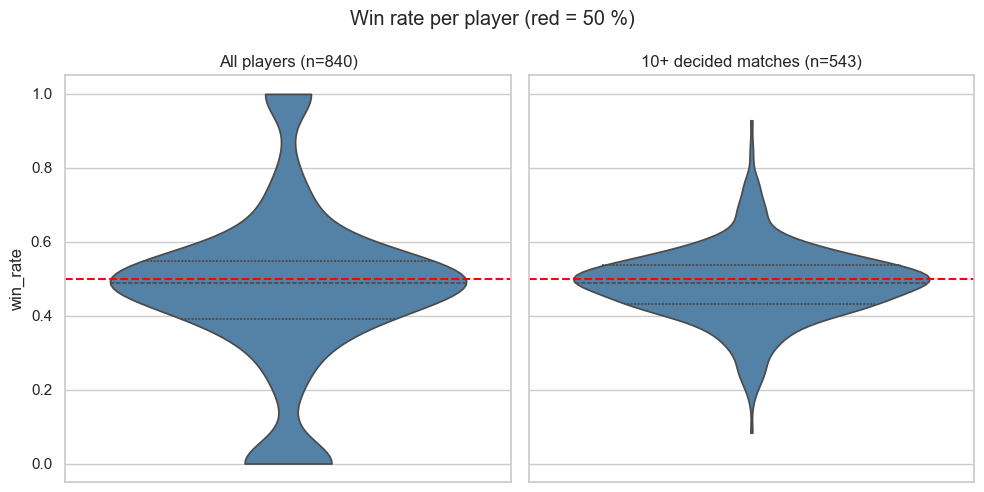

shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 543.0    │
│ null_count ┆ 0.0      │
│ mean       ┆ 0.48475  │
│ std        ┆ 0.099818 │
│ min        ┆ 0.083333 │
│ 25%        ┆ 0.430556 │
│ 50%        ┆ 0.489633 │
│ 75%        ┆ 0.535971 │
│ max        ┆ 0.928571 │
└────────────┴──────────┘


In [5]:
df_winrate: pl.DataFrame = df_player_stats.drop_nulls('win_rate')
df_winrate_10: pl.DataFrame = df_winrate.filter(pl.col('decided') >= 10)

ex.violin_pair(
    [(df_winrate, f'All players (n={df_winrate.height})'), (df_winrate_10, f'10+ decided matches (n={df_winrate_10.height})')],
    y='win_rate', reference=0.5, suptitle='Win rate per player (red = 50 %)',
)
plt.show()

print(df_winrate_10['win_rate'].describe())

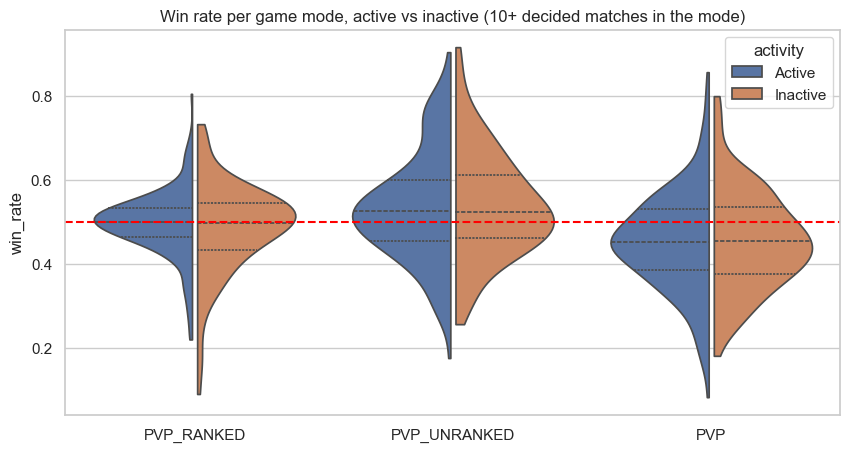

gamemode,activity,players,win_rate_median,win_rate_mean,win_rate_std
str,str,u32,f64,f64,f64
"""PVP""","""Active""",201,0.453,0.453,0.119
"""PVP""","""Inactive""",140,0.455,0.457,0.117
"""PVP_RANKED""","""Active""",190,0.502,0.497,0.078
"""PVP_RANKED""","""Inactive""",102,0.498,0.486,0.108
"""PVP_UNRANKED""","""Active""",160,0.527,0.535,0.13
"""PVP_UNRANKED""","""Inactive""",99,0.524,0.541,0.126


In [6]:
# win rate per game mode, split by active / inactive (a player appears once per mode played)
df_plot = df_player_mode.filter(pl.col('decided') >= MIN_DECIDED_PLOT).to_pandas()
fig, ax = plt.subplots(figsize=(10, 5))
ex.split_violin(ax, df_plot, y='win_rate', x='gamemode', order=GAMEMODE_ORDER)
ax.axhline(0.5, color='red', linestyle='--')
ax.set_title(f'Win rate per game mode, active vs inactive ({MIN_DECIDED_PLOT}+ decided matches in the mode)')
ax.set_xlabel('')
plt.show()

df_player_mode.filter(pl.col('decided') >= MIN_DECIDED_PLOT).group_by('gamemode', 'activity').agg(
    pl.len().alias('players'),
    pl.col('win_rate').median().round(3).alias('win_rate_median'),
    pl.col('win_rate').mean().round(3).alias('win_rate_mean'),
    pl.col('win_rate').std().round(3).alias('win_rate_std'),
).sort('gamemode', 'activity')

Observation :
- The median win rate is 49%: a typical player wins about half of his games.
- The big spread over all players comes from players with very few games. With 10+ games it is close to 50% (most players between 31% and 65%).
- By mode: ranked 50%, unranked 53%, PVP 45%.
- Active and inactive players have the same win rate in every mode.

## 2. K/D ratio per player

players without K/D (no death at all or no kills/death recorded): 7
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 833.0    │
│ null_count ┆ 0.0      │
│ mean       ┆ 0.897528 │
│ std        ┆ 0.587972 │
│ min        ┆ 0.0      │
│ 25%        ┆ 0.52381  │
│ 50%        ┆ 0.862825 │
│ 75%        ┆ 1.171053 │
│ max        ┆ 5.0      │
└────────────┴──────────┘
share of players with K/D >= 1: 0.377


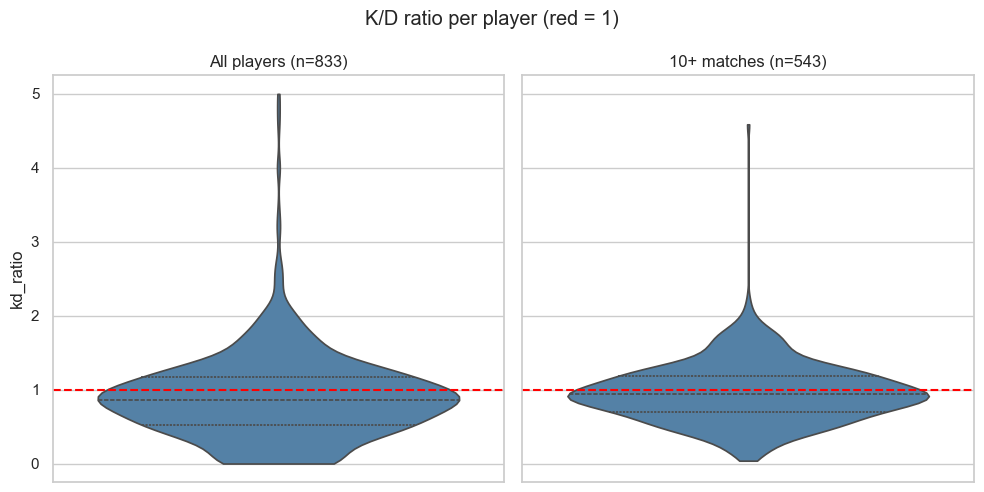

In [7]:
df_kd: pl.DataFrame = df_player_stats.drop_nulls('kd_ratio')
print('players without K/D (no death at all or no kills/death recorded):', df_player_stats.height - df_kd.height)
print(df_kd['kd_ratio'].describe())
print('share of players with K/D >= 1:', round((df_kd['kd_ratio'] >= 1).mean(), 3))

df_kd_10: pl.DataFrame = df_kd.filter(pl.col('matches_with_kd') >= 10)
ex.violin_pair(
    [(df_kd, f'All players (n={df_kd.height})'), (df_kd_10, f'10+ matches (n={df_kd_10.height})')],
    y='kd_ratio', reference=1, suptitle='K/D ratio per player (red = 1)',
)
plt.show()

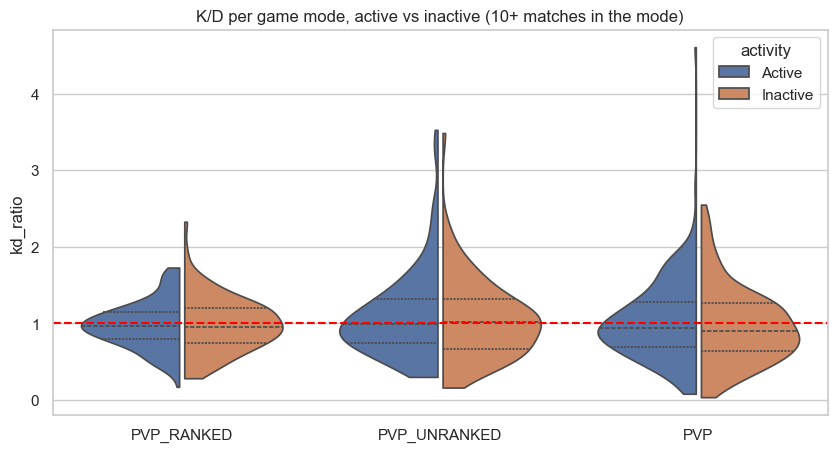

gamemode,activity,players,kd_median,kd_mean,kd_std
str,str,u32,f64,f64,f64
"""PVP""","""Active""",201,0.942,1.037,0.525
"""PVP""","""Inactive""",140,0.898,0.973,0.494
"""PVP_RANKED""","""Active""",189,0.971,0.981,0.303
"""PVP_RANKED""","""Inactive""",102,0.953,0.989,0.354
"""PVP_UNRANKED""","""Active""",160,0.992,1.099,0.554
"""PVP_UNRANKED""","""Inactive""",99,1.022,1.048,0.516


In [8]:
# K/D per game mode, split by active / inactive
df_plot = df_player_mode.drop_nulls('kd_ratio').filter(pl.col('matches_with_kd') >= MIN_DECIDED_PLOT).to_pandas()
fig, ax = plt.subplots(figsize=(10, 5))
ex.split_violin(ax, df_plot, y='kd_ratio', x='gamemode', order=GAMEMODE_ORDER)
ax.axhline(1, color='red', linestyle='--')
ax.set_title(f'K/D per game mode, active vs inactive ({MIN_DECIDED_PLOT}+ matches in the mode)')
ax.set_xlabel('')
plt.show()

df_player_mode.drop_nulls('kd_ratio').filter(pl.col('matches_with_kd') >= MIN_DECIDED_PLOT).group_by('gamemode', 'activity').agg(
    pl.len().alias('players'),
    pl.col('kd_ratio').median().round(3).alias('kd_median'),
    pl.col('kd_ratio').mean().round(3).alias('kd_mean'),
    pl.col('kd_ratio').std().round(3).alias('kd_std'),
).sort('gamemode', 'activity')

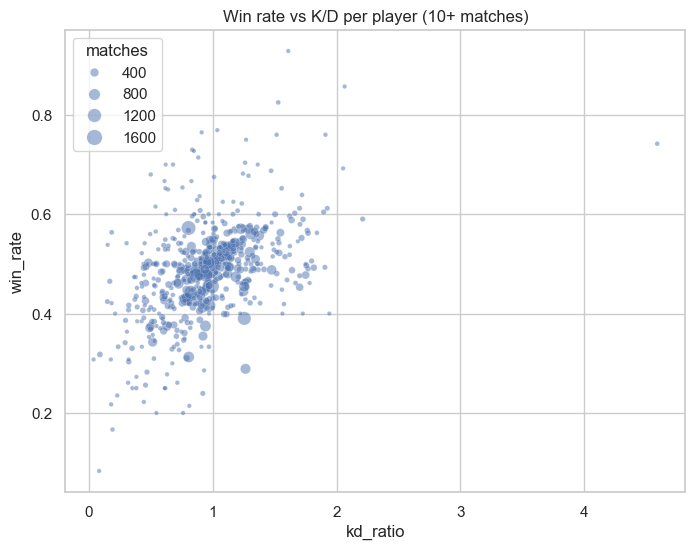

correlation win rate / K/D: 0.475


In [9]:
# win rate vs K/D, players with 10+ matches
df_scatter = df_kd.filter(pl.col('decided') >= 10, pl.col('matches_with_kd') >= 10).to_pandas()
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_scatter, x='kd_ratio', y='win_rate', size='matches', sizes=(10, 150), alpha=0.5, ax=ax)
ax.set_title('Win rate vs K/D per player (10+ matches)')
plt.show()
print('correlation win rate / K/D:', round(df_scatter['win_rate'].corr(df_scatter['kd_ratio']), 3))

Observation :
- The median K/D is 0.86: most players die more than they kill (only 37.7% are at 1 or more).
- Active and inactive players have the same K/D in every mode.
- K/D goes with win rate (correlation 0.48 for players with 10+ games), as expected.

## 3. Longest win and loss streaks (players with at least 3 matches)

Matches are sorted by date. A streak is a run of the same result in a row; a draw / other breaks it.

In [10]:
df_eligible: pl.DataFrame = df_player_stats.filter(pl.col('matches') >= MIN_MATCHES).select('playerid', 'matches')
print(f'eligible players (>= {MIN_MATCHES} matches):', df_eligible.height, 'of', df_player_stats.height)

df_streaks: pl.DataFrame = ex.max_streaks(df_player_matches, df_eligible)
print(df_streaks.select('matches', 'max_win_streak', 'max_loss_streak').describe())
df_streaks.head(10)

eligible players (>= 3 matches): 700 of 840
shape: (9, 4)
┌────────────┬────────────┬────────────────┬─────────────────┐
│ statistic  ┆ matches    ┆ max_win_streak ┆ max_loss_streak │
│ ---        ┆ ---        ┆ ---            ┆ ---             │
│ str        ┆ f64        ┆ f64            ┆ f64             │
╞════════════╪════════════╪════════════════╪═════════════════╡
│ count      ┆ 700.0      ┆ 700.0          ┆ 700.0           │
│ null_count ┆ 0.0        ┆ 0.0            ┆ 0.0             │
│ mean       ┆ 136.492857 ┆ 4.877143       ┆ 5.174286        │
│ std        ┆ 228.163192 ┆ 2.927213       ┆ 3.169223        │
│ min        ┆ 3.0        ┆ 0.0            ┆ 0.0             │
│ 25%        ┆ 11.0       ┆ 3.0            ┆ 3.0             │
│ 50%        ┆ 46.0       ┆ 4.0            ┆ 5.0             │
│ 75%        ┆ 151.0      ┆ 7.0            ┆ 7.0             │
│ max        ┆ 1974.0     ┆ 29.0           ┆ 20.0            │
└────────────┴────────────┴────────────────┴────────────────

playerid,matches,max_win_streak,max_loss_streak
str,u32,u32,u32
"""413153a8-703c-4660-82c0-216bd2…",1974,11,9
"""a93be58b-8545-41b1-b97a-6bbcf0…",1344,8,10
"""899c022b-b7a2-46df-850b-2ac52e…",1342,29,9
"""dd8f00e6-29f6-47a5-b041-c0fd16…",1339,7,9
"""5303fa40-25a1-424f-b698-3c4d4a…",1268,9,11
"""65ca9afb-240d-4f3f-bbc9-11fd60…",1223,10,7
"""95448b41-3b95-4a49-99e6-74d17e…",1191,8,11
"""04964954-a0f6-4749-aefc-f76c4d…",1166,7,20
"""71fa17e1-6236-4259-8efe-80d5f2…",1156,10,7


In [11]:
# sanity check: recompute the streaks with plain python on 50 random players
rng = np.random.default_rng(0)
sample_ids = rng.choice(df_streaks['playerid'].to_numpy(), size=50, replace=False)
mismatches = 0
for player_id in sample_ids:
    results = df_player_matches.filter(pl.col('playerid') == player_id).sort('match_datetime', 'matchid')['victory'].to_list()
    expected = ex.python_streaks(results)
    got = df_streaks.filter(pl.col('playerid') == player_id).select('max_win_streak', 'max_loss_streak').row(0)
    mismatches += expected != got
print('mismatches on 50 random players:', mismatches)
assert mismatches == 0

mismatches on 50 random players: 0


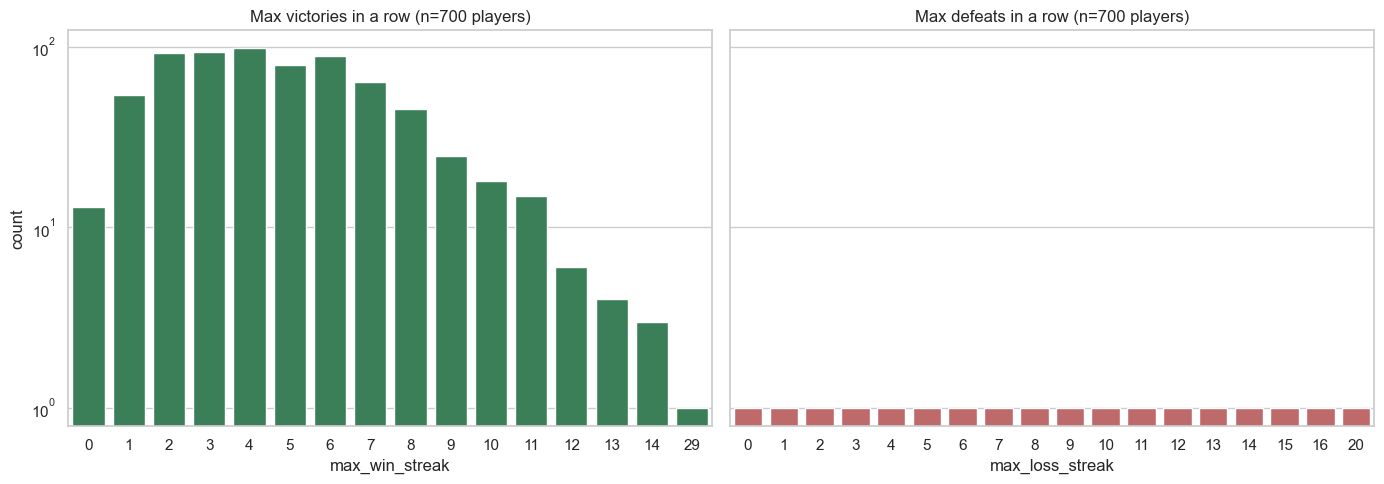

matches_bucket,players,win_streak_mean,win_streak_max,loss_streak_mean,loss_streak_max
cat,u32,f64,u32,f64,u32
"""100+""",235,7.35,29,7.88,20
"""30-99""",177,5.05,13,5.54,14
"""3-9""",157,2.15,9,1.98,7
"""10-29""",131,3.48,13,3.66,11


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, column, color, title in [
    (axes[0], 'max_win_streak', 'seagreen', 'Max victories in a row'),
    (axes[1], 'max_loss_streak', 'indianred', 'Max defeats in a row'),
]:
    sns.countplot(data=df_streaks.to_pandas(), x=column, color=color, ax=ax)
    ax.set_title(f'{title} (n={df_streaks.height} players)')
    ax.set_yscale('log')
fig.tight_layout()
plt.show()

# streaks grow with the number of matches: compare by activity level
(
    df_streaks.with_columns(
        pl.col('matches').cut([9, 29, 99], labels=['3-9', '10-29', '30-99', '100+']).alias('matches_bucket')
    )
    .group_by('matches_bucket')
    .agg(
        pl.len().alias('players'),
        pl.col('max_win_streak').mean().round(2).alias('win_streak_mean'),
        pl.col('max_win_streak').max().alias('win_streak_max'),
        pl.col('max_loss_streak').mean().round(2).alias('loss_streak_mean'),
        pl.col('max_loss_streak').max().alias('loss_streak_max'),
    )
    .sort('players', descending=True)
)

In [13]:
print('top win streaks')
print(df_streaks.sort('max_win_streak', descending=True).head(5))
print('top loss streaks')
print(df_streaks.sort('max_loss_streak', descending=True).head(5))

top win streaks
shape: (5, 4)
┌─────────────────────────────────┬─────────┬────────────────┬─────────────────┐
│ playerid                        ┆ matches ┆ max_win_streak ┆ max_loss_streak │
│ ---                             ┆ ---     ┆ ---            ┆ ---             │
│ str                             ┆ u32     ┆ u32            ┆ u32             │
╞═════════════════════════════════╪═════════╪════════════════╪═════════════════╡
│ 899c022b-b7a2-46df-850b-2ac52e… ┆ 1342    ┆ 29             ┆ 9               │
│ 03b78c22-2b26-4195-9597-2a3b01… ┆ 306     ┆ 14             ┆ 6               │
│ 40a8ca30-92bc-44a0-9c12-c05420… ┆ 204     ┆ 14             ┆ 6               │
│ 15b37e0b-0112-45a2-873c-6dc2c6… ┆ 153     ┆ 14             ┆ 6               │
│ f4887f10-eb20-42a9-b5cc-c86d4a… ┆ 445     ┆ 13             ┆ 6               │
└─────────────────────────────────┴─────────┴────────────────┴─────────────────┘
top loss streaks
shape: (5, 4)
┌─────────────────────────────────┬─────────┬───

Observation :
- The median player has a best run of 4 wins and 5 losses in a row (700 players with 3+ matches).
- The more a player plays, the longer his streaks (best win streak 2.2 on average for 3-9 matches, 7.4 for 100+).
- Two outliers to check: a win streak of 29 (next best is 14) and a loss streak of 20.
- A streak of 0 means the player never won (or never lost).